# Exploratory Data Analysis (EDA) — UMKM Kuliner Surabaya Timur

Analisis eksplorasi pada 4 modalitas data bersih di zona `data/clean/`:
1. **Tabular:** Profil UMKM terverifikasi dari Google Places API (6 kecamatan Surabaya Timur).
2. **Teks Ulasan:** Ulasan asli dengan pelestarian bahasa default (`en`, `id`, `jv`) dan masking PII.
3. **Citra:** Foto bersih terfilter CLIP (`sample/keep` vs `sample/reject`) dan blur wajah OpenCV.
4. **Dokumen:** Berkas perizinan dan administrasi penelitian.

In [1]:
import json
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ROOT_DIR = Path.cwd().resolve()
if not (ROOT_DIR / 'data').exists() and (ROOT_DIR.parent.parent / 'data').exists():
    ROOT_DIR = ROOT_DIR.parent.parent
if str(ROOT_DIR) not in sys.path:
    sys.path.insert(0, str(ROOT_DIR))

CLEAN_DIR = ROOT_DIR / 'data' / 'clean'
GOLD_DIR = ROOT_DIR / 'data' / 'gold'
REPORTS_DIR = ROOT_DIR / 'peta-digital-umkm' / 'reports'
GDRIVE_OUT = Path('G:/My Drive/Iqbal-EDA')
OUT_DIR = GDRIVE_OUT if GDRIVE_OUT.parent.exists() else (REPORTS_DIR / 'iqbal-eda')
OUT_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 120

def save_and_show(filename: str) -> None:
    out_path = OUT_DIR / filename
    plt.tight_layout()
    plt.savefig(out_path, dpi=200, bbox_inches='tight')
    print(f'Saved: {out_path}')
    plt.show()

print(f'Project Root : {ROOT_DIR}')
print(f'Clean Data   : {CLEAN_DIR}')
print(f'Output Dir   : {OUT_DIR}')

Project Root : C:\big-data-analytic
Clean Data   : C:\big-data-analytic\data\clean
Output Dir   : G:\My Drive\Iqbal-EDA


In [2]:
df_umkm = pd.read_parquet(CLEAN_DIR / 'umkm.parquet')
df_ulasan = pd.read_parquet(CLEAN_DIR / 'ulasan.parquet')
df_foto = pd.read_parquet(CLEAN_DIR / 'foto.parquet')
df_dokumen = pd.read_parquet(CLEAN_DIR / 'dokumen.parquet')

summary_tbl = pd.DataFrame([
    {'Modalitas': 'Tabular UMKM', 'Jumlah Baris': len(df_umkm), 'Keterangan': '100% entitas Google Places API asli'},
    {'Modalitas': 'Teks Ulasan', 'Jumlah Baris': len(df_ulasan), 'Keterangan': 'Bahasa asli dipertahankan (en/id/jv)'},
    {'Modalitas': 'Citra Bersih', 'Jumlah Baris': len(df_foto), 'Keterangan': 'Lolos CLIP filter + blur wajah OpenCV'},
    {'Modalitas': 'Dokumen Izin', 'Jumlah Baris': len(df_dokumen), 'Keterangan': 'PDF perizinan penelitian'},
])
display(summary_tbl)

,Modalitas,Jumlah Baris,Keterangan
0,Tabular UMKM,385,100% entitas Google Places API asli
1,Teks Ulasan,1164,Bahasa asli dipertahankan (en/id/jv)
2,Citra Bersih,549,Lolos CLIP filter + blur wajah OpenCV
3,Dokumen Izin,3,PDF perizinan penelitian


## 1. Modalitas Tabular — Sebaran Wilayah & Rating

Saved: G:\My Drive\Iqbal-EDA\01_distribusi_umkm_kecamatan.png


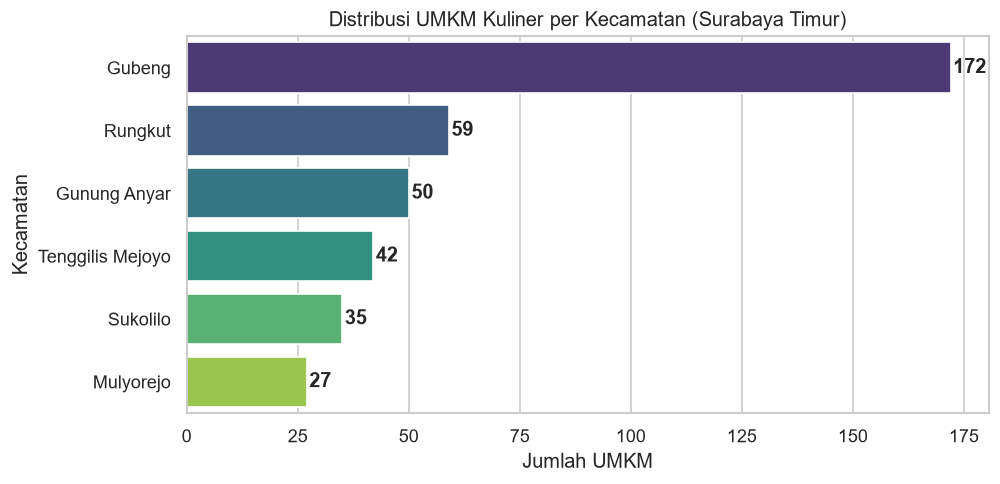

Statistik Rating Google Maps:
count    383.000
mean       4.575
std        0.343
min        2.400
25%        4.400
50%        4.600
75%        4.800
max        5.000
Name: rating, dtype: float64


In [3]:
kec_counts = df_umkm['kecamatan'].value_counts()
plt.figure(figsize=(8.5, 4.2))
sns.barplot(x=kec_counts.values, y=kec_counts.index, hue=kec_counts.index, palette='viridis', legend=False)
plt.title('Distribusi UMKM Kuliner per Kecamatan (Surabaya Timur)')
plt.xlabel('Jumlah UMKM')
plt.ylabel('Kecamatan')
for idx, val in enumerate(kec_counts.values):
    plt.text(val + 0.6, idx, str(val), va='center', fontweight='bold')
save_and_show('01_distribusi_umkm_kecamatan.png')

print('Statistik Rating Google Maps:')
print(df_umkm['rating'].describe().round(3))

Saved: G:\My Drive\Iqbal-EDA\02_distribusi_rating.png


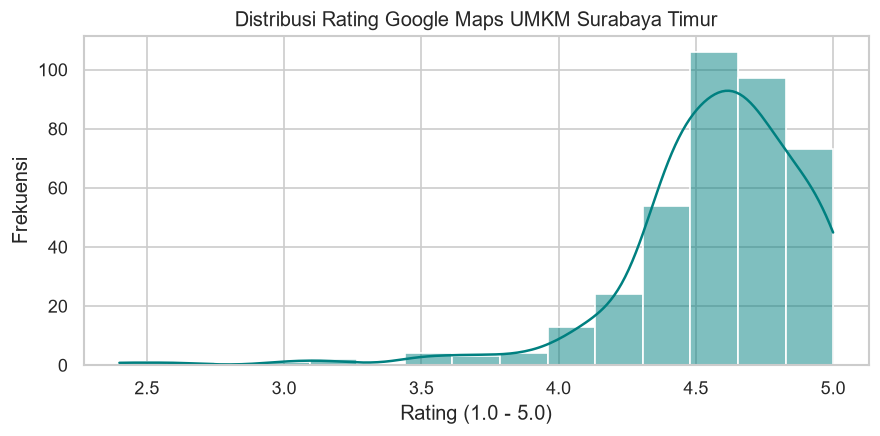

In [4]:
plt.figure(figsize=(7.5, 3.8))
sns.histplot(df_umkm['rating'].dropna(), bins=15, kde=True, color='teal')
plt.title('Distribusi Rating Google Maps UMKM Surabaya Timur')
plt.xlabel('Rating (1.0 - 5.0)')
plt.ylabel('Frekuensi')
save_and_show('02_distribusi_rating.png')

## 2. Modalitas Teks — Bahasa Asli & Sinyal Digital

,Bahasa,Jumlah Ulasan,Persentase (%)
0,en,1040,89.35
1,id,124,10.65


Saved: G:\My Drive\Iqbal-EDA\03_frekuensi_indikator_ulasan.png


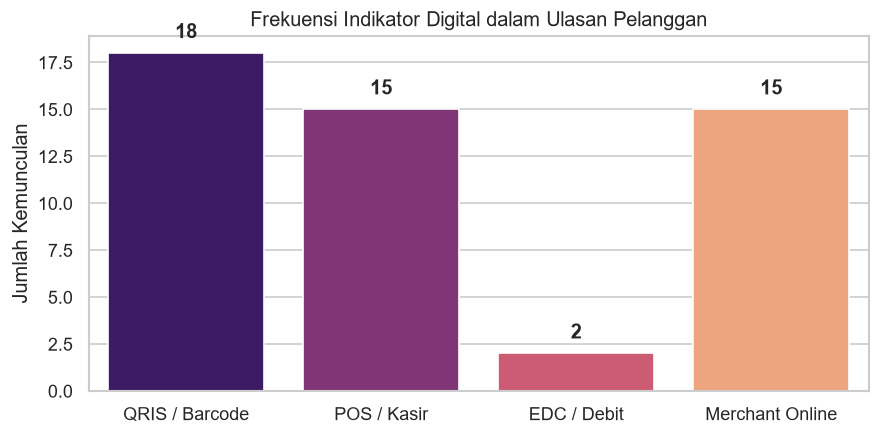

In [5]:
lang_counts = df_ulasan['bahasa'].value_counts().rename_axis('Bahasa').reset_index(name='Jumlah Ulasan')
lang_counts['Persentase (%)'] = (lang_counts['Jumlah Ulasan'] / len(df_ulasan) * 100).round(2)
display(lang_counts)

sinyal_cols = ['mention_qris', 'mention_pos', 'mention_edc', 'mention_online']
sinyal_sum = df_ulasan[sinyal_cols].sum()
labels = ['QRIS / Barcode', 'POS / Kasir', 'EDC / Debit', 'Merchant Online']
plt.figure(figsize=(7.5, 3.8))
sns.barplot(x=labels, y=sinyal_sum.values, hue=labels, palette='magma', legend=False)
plt.title('Frekuensi Indikator Digital dalam Ulasan Pelanggan')
plt.ylabel('Jumlah Kemunculan')
for i, v in enumerate(sinyal_sum.values):
    plt.text(i, v + 0.8, str(int(v)), ha='center', fontweight='bold')
save_and_show('03_frekuensi_indikator_ulasan.png')

## 3. Modalitas Citra — Audit CLIP (`keep` vs `reject`), Indikator YOLO, & Privasi

Ringkasan Audit CLIP (SampleGuidedFilter): {
  "audit_strict": {
    "kept": 417,
    "rejected_visual": 58,
    "rejected_region": 65,
    "kept_bytes": 116624900
  },
  "survey_bytes": 70085648,
  "expansion": {
    "downloaded_kept": 88,
    "downloaded_rejected": 183,
    "added_bytes": 35721426
  },
  "final_clean_mb": 212.13
}


Saved: G:\My Drive\Iqbal-EDA\05_distribusi_indikator_citra_yolo.png


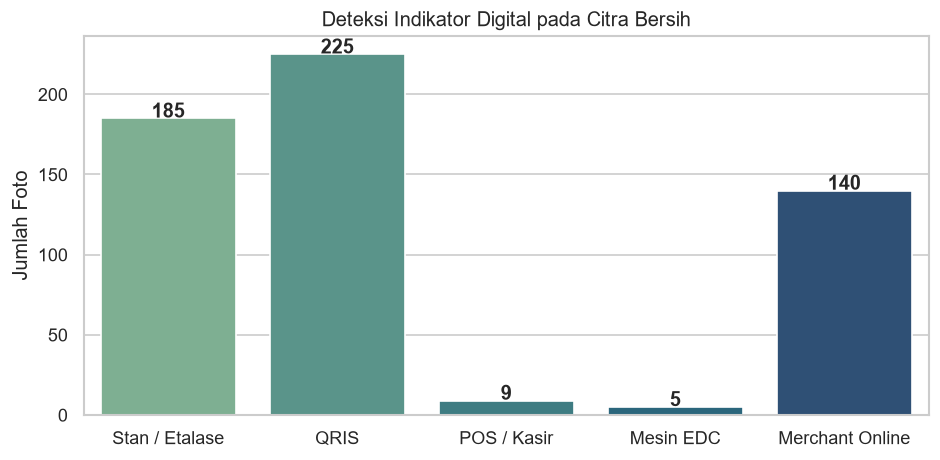

Total wajah diburamkan (OpenCV) : 824 wajah
Foto dengan wajah disanitasi    : 311 foto


In [6]:
audit_path = REPORTS_DIR / 'yolo' / 'filter' / 'clip_audit_summary.json'
if audit_path.exists():
    with open(audit_path, 'r', encoding='utf-8') as f:
        audit_info = json.load(f)
    print('Ringkasan Audit CLIP (SampleGuidedFilter):', json.dumps(audit_info, indent=2))

ind_cols = ['has_stan', 'has_qris', 'has_pos', 'has_edc', 'has_merchant_online']
ind_labels = ['Stan / Etalase', 'QRIS', 'POS / Kasir', 'Mesin EDC', 'Merchant Online']
ind_counts = [int(df_foto[c].sum()) if c in df_foto.columns else 0 for c in ind_cols]

plt.figure(figsize=(8.0, 4.0))
sns.barplot(x=ind_labels, y=ind_counts, hue=ind_labels, palette='crest', legend=False)
plt.title('Deteksi Indikator Digital pada Citra Bersih')
plt.ylabel('Jumlah Foto')
for i, v in enumerate(ind_counts):
    plt.text(i, v + 0.5, str(v), ha='center', fontweight='bold')
save_and_show('05_distribusi_indikator_citra_yolo.png')

print(f"Total wajah diburamkan (OpenCV) : {int(df_foto['face_blurred_count'].sum())} wajah")
print(f"Foto dengan wajah disanitasi    : {int((df_foto['face_blurred_count'] > 0).sum())} foto")

## 4. Modalitas Dokumen Perizinan

In [7]:
display(df_dokumen[['dok_id', 'file_name', 'pages', 'file_size_kb', 'institusi']])

,dok_id,file_name,pages,file_size_kb,institusi
0,DOK_01,Proposal_Izin_Penelitian.pdf,3,126.11,Dinas Koperasi UKM dan Perdagangan Kota Suraba...
1,DOK_02,Surat_Dinas_Koperasi.pdf,2,181.57,Dinas Koperasi UKM dan Perdagangan Kota Suraba...
2,DOK_03,surat_izin_penelitian.pdf,2,138.90,Dinas Koperasi UKM dan Perdagangan Kota Suraba...
